# Tomorrow's temperature: which city should Sydney watch?

**Adding Melbourne's temperatures to the table cuts the miss on tomorrow's high in Sydney by 14%. Perth, on the far side of the continent, helps most two and three days out. Darwin makes the forecast worse.**

A forecast made from one city's own record soon runs out of things to learn. But weather travels, and across southern Australia it mostly travels from west to east, so another city's today can be Sydney's tomorrow. TimeGym forecasts the columns of a table together: each column's forecast can use every column's past, and only the past. Testing whether a second series helps is then a matter of adding a column.

*Data: the highest temperature of each day in eight Australian cities, May 2015 to April 2017, Bureau of Meteorology data from the Monash Time Series Forecasting Archive ([source and license](data/README.md#city-temperatures)). To run this notebook yourself, see [Run an example yourself](../docs/examples.md#run-an-example-yourself).*

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.linear_model import LinearRegression

from timegym import LastValueForecaster, Pipeline, cases_from_series
from timegym.statistics import paired_t_interval

from example_data import load  # examples/example_data.py, next to this notebook

plt.rcParams.update({"figure.figsize": (12, 4), "figure.dpi": 110, "font.size": 11,
                     "figure.facecolor": "white", "axes.facecolor": "white",
                     "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": False, "legend.frameon": False, "axes.titlelocation": "left"})

## The job

Forecast the high in Sydney for each of the next three days. The table has one column per city and one row per day.

,Sydney,Melbourne,Adelaide,Canberra,Hobart,Perth,Brisbane,Darwin
date,,,,,,,,
2015-05-02,20.9,18.6,19.9,23.3,19.2,22.4,25.0,32.7
2015-05-03,21.8,22.5,26.7,21.5,17.5,17.4,25.4,32.0
2015-05-04,27.5,16.8,17.5,20.8,17.7,20.2,25.8,33.1


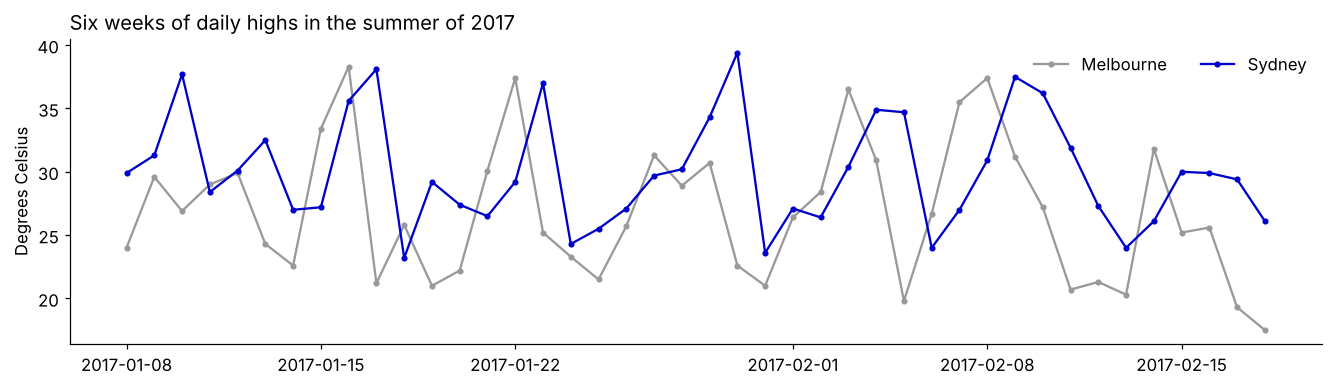

725 days, 02 May 2015 to 25 April 2017.
Correlation of tomorrow's high in Sydney with today's high in
  Sydney: 0.69    Melbourne: 0.79


In [2]:
highs = load("city-temperatures")
display(highs.head(3))

weeks = highs.loc["2017-01-08":"2017-02-18"]
fig, ax = plt.subplots(figsize=(12, 3.4), layout="constrained")
ax.plot(weeks.index, weeks["Melbourne"], color="0.6", marker="o", markersize=3, label="Melbourne")
ax.plot(weeks.index, weeks["Sydney"], color="#0000CC", marker="o", markersize=3, label="Sydney")
ax.set(title="Six weeks of daily highs in the summer of 2017", ylabel="Degrees Celsius")
ax.legend(loc="upper right", ncols=2)
plt.show()

tomorrow = highs["Sydney"].shift(-1)
print(f"{len(highs)} days, {highs.index[0]:%d %B %Y} to {highs.index[-1]:%d %B %Y}.")
print("Correlation of tomorrow's high in Sydney with today's high in")
print(f"  Sydney: {tomorrow.corr(highs['Sydney']):.2f}    Melbourne: {tomorrow.corr(highs['Melbourne']):.2f}")
assert tomorrow.corr(highs["Melbourne"]) > tomorrow.corr(highs["Sydney"])

Melbourne's peaks tend to show up in Sydney a day later. Over the two years, today's high in Melbourne says more about tomorrow's high in Sydney than today's high in Sydney does.

## Sydney on its own

First, two forecasters that see only Sydney's record: **same as today**, and a **regression** on the last three days. Each forecasts the next three days, starting from every day of the second year, and we look at the average miss in degrees by how many days ahead the forecast is.

In [3]:
days_ahead, first = 3, 365   # one year of history before the first forecast


def sydney_misses(cities, pipeline=None):
    # Forecast these cities together from every day of the second year.
    # Returns Sydney's miss: one row per forecast, one column per day ahead.
    assert cities[0] == "Sydney"
    table = highs[cities]
    cases = cases_from_series(table, origins=range(first, len(table) - days_ahead + 1), horizon=days_ahead, name="highs")
    pipeline = Pipeline(LinearRegression(), window_length=3) if pipeline is None else pipeline
    run = pipeline.run(cases=cases, keep_data=True)
    counts = run.report.summary["status_counts"]
    assert counts["ERROR"] == counts["FAIL"] == 0   # every forecast passed the output checks
    return np.array([np.abs(entry.forecast.point[:, 0] - entry.case.observed["Sydney"].to_numpy()) for entry in run.cases])


def by_day(misses):
    return pd.Series(misses.mean(axis=0), index=["Tomorrow", "In 2 days", "In 3 days"])


alone = sydney_misses(["Sydney"])
table = pd.DataFrame({"Same as today": by_day(sydney_misses(["Sydney"], Pipeline(LastValueForecaster()))),
                      "Regression on Sydney": by_day(alone)}).T
display(table.round(2).rename_axis("Average miss in degrees"))
print(f"{len(alone)} forecasts of {days_ahead} days each.")
assert (table.loc["Regression on Sydney"] < table.loc["Same as today"]).all()

,Tomorrow,In 2 days,In 3 days
Average miss in degrees,,,
Same as today,2.63,3.24,3.09
Regression on Sydney,2.35,2.63,2.63


358 forecasts of 3 days each.


The regression misses tomorrow's high by 2.35 degrees on average, and by 2.63 after that. This is the number to beat.

## Add a city

Now the same regression, the same days, and one change: the table has two columns. With several columns the pipeline forecasts them together. The regression for each city sees the last three days of both, so Sydney's forecast can lean on what Melbourne just did. Each case holds only days before the forecast starts, for every column, so there is no way for tomorrow's Melbourne to slip in.

We still score Sydney alone. Because both runs forecast the same days, the gain can be taken forecast by forecast, and `paired_t_interval` gives the average gain with a 95% interval.

In [4]:
def gain(misses, base=None):
    base = alone if base is None else base
    rows = {}
    for day, label in enumerate(["Tomorrow", "In 2 days", "In 3 days"]):
        interval = paired_t_interval(base[:, day] - misses[:, day])
        rows[label] = {"Miss alone": base[:, day].mean(), "Miss with the city": misses[:, day].mean(),
                       "Cut (%)": 100 * (1 - misses[:, day].mean() / base[:, day].mean()),
                       "Cut in degrees": interval["mean"], "Low": interval["ci95"][0], "High": interval["ci95"][1]}
    return pd.DataFrame(rows).T


with_melbourne = sydney_misses(["Sydney", "Melbourne"])
melbourne = gain(with_melbourne)
display(melbourne.round({"Miss alone": 2, "Miss with the city": 2, "Cut (%)": 0, "Cut in degrees": 2, "Low": 2, "High": 2}))
assert 12 < melbourne.loc["Tomorrow", "Cut (%)"] < 16 and melbourne.loc["Tomorrow", "Low"] > 0.1
assert melbourne.loc["In 3 days", "Low"] < 0 < melbourne.loc["In 3 days", "Cut in degrees"]

,Miss alone,Miss with the city,Cut (%),Cut in degrees,Low,High
Tomorrow,2.35,2.02,14.0,0.33,0.17,0.50
In 2 days,2.63,2.41,8.0,0.22,0.09,0.35
In 3 days,2.63,2.53,4.0,0.10,-0.01,0.21


One more column and tomorrow's miss falls from 2.35 to 2.02 degrees, 14% less. The interval for that cut runs from 0.17 to 0.50 degrees, well clear of zero. The help fades with distance in time: 8% in two days, and by the third day the interval reaches zero.

## Which city?

Melbourne was a guess. The same two lines of code can try every other city in the table, one at a time.

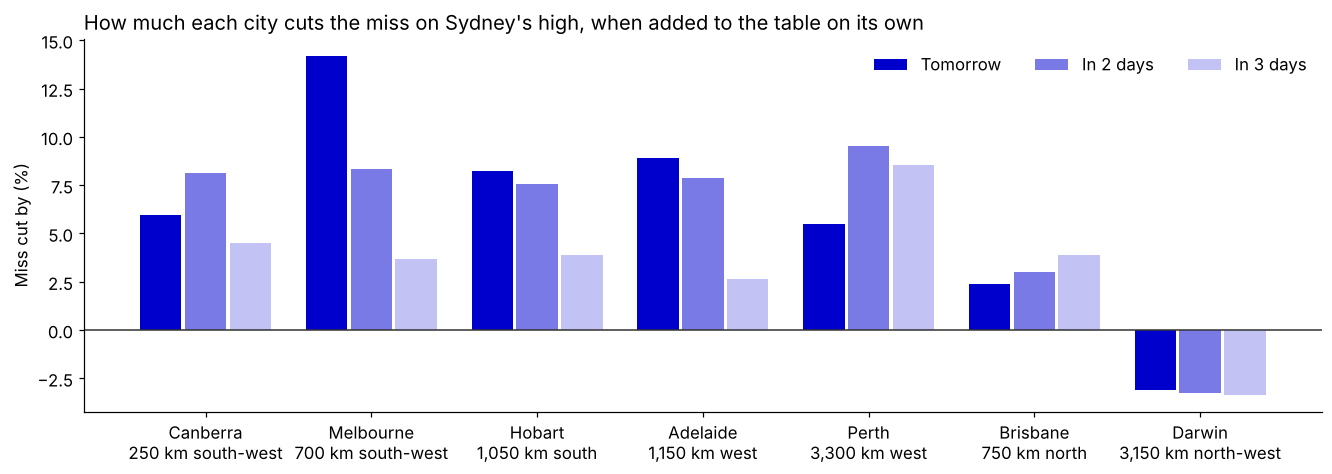

,Tomorrow,In 2 days,In 3 days
Miss on Sydney's high cut by (%),,,
Canberra,6,8,5
Melbourne,14,8,4
Hobart,8,8,4
Adelaide,9,8,3
Perth,6,10,9
Brisbane,2,3,4
Darwin,-3,-3,-3


Cities whose effect is clear of zero, by day:
  Tomorrow: Melbourne, Hobart, Adelaide, Perth, Darwin
  In 2 days: Canberra, Melbourne, Hobart, Adelaide, Perth, Darwin
  In 3 days: Perth, Darwin


In [5]:
where = {"Canberra": "250 km south-west", "Melbourne": "700 km south-west", "Hobart": "1,050 km south",
         "Adelaide": "1,150 km west", "Perth": "3,300 km west", "Brisbane": "750 km north", "Darwin": "3,150 km north-west"}
gains = {city: gain(sydney_misses(["Sydney", city])) for city in where}
cut = pd.DataFrame({city: result["Cut (%)"] for city, result in gains.items()}).T
clear = pd.DataFrame({city: (result["Low"] > 0) | (result["High"] < 0) for city, result in gains.items()}).T

fig, ax = plt.subplots(figsize=(12, 4.2), layout="constrained")
shades = {"Tomorrow": "#0000CC", "In 2 days": "#7A7AE6", "In 3 days": "#C2C2F5"}
for offset, (day, color) in enumerate(shades.items()):
    ax.bar(np.arange(len(cut)) + 0.27 * (offset - 1), cut[day], width=0.25, color=color, label=day)
ax.axhline(0, color="0.2", linewidth=1)
ax.set_xticks(range(len(cut)), [f"{city}\n{where[city]}" for city in cut.index])
ax.set(title="How much each city cuts the miss on Sydney's high, when added to the table on its own", ylabel="Miss cut by (%)")
ax.legend(loc="upper right", ncols=3)
plt.show()
display(cut.round(0).astype(int).rename_axis("Miss on Sydney's high cut by (%)"))
print("Cities whose effect is clear of zero, by day:")
for day in cut.columns:
    print(f"  {day}: {', '.join(clear.index[clear[day]])}")

assert cut["Tomorrow"].idxmax() == "Melbourne" and cut["In 3 days"].idxmax() == "Perth"
assert (cut.loc["Darwin"] < 0).all() and clear.loc["Darwin"].all() and not clear.loc["Brisbane"].any()

The picture has geography in it.

- **Melbourne** helps most for tomorrow. It is a day upwind.
- **Canberra** is the nearest and helps less than half as much for tomorrow. Being close is not the same as being upwind.
- **Perth** is 3,300 kilometers to the west. It helps least of the southern cities for tomorrow and most for the days after: what happens in Perth takes a few days to cross the continent.
- **Brisbane**, to the north, adds a few percent that cannot be told from zero.
- **Darwin**, in the tropics, makes every forecast about 3% worse, and that effect is clear of zero. A column with nothing to say is not free: the regression has to learn that from one to two years of days, and what it learns instead is noise.

Nothing told the regression where the cities are. It found the direction the weather travels in two columns of numbers.

## All of them at once?

If one city helps, eight might help more. Or the Darwin effect might add up.

In [6]:
choices = {"Sydney alone": ["Sydney"], "With Melbourne": ["Sydney", "Melbourne"],
           "With Melbourne and Perth": ["Sydney", "Melbourne", "Perth"], "All eight cities": list(highs.columns)}
together = pd.DataFrame({name: by_day(alone if cities == ["Sydney"] else sydney_misses(cities)) for name, cities in choices.items()}).T
together["Columns"] = [len(cities) for cities in choices.values()]
display(together.round(2).rename_axis("Average miss in degrees"))
best_two = together.loc["With Melbourne and Perth"]
assert (together.loc["All eight cities"].iloc[:3] < together.loc["With Melbourne"].iloc[:3] + 0.005).all()
assert (best_two.iloc[:3] - together.loc["All eight cities"].iloc[:3]).abs().max() < 0.03

,Tomorrow,In 2 days,In 3 days,Columns
Average miss in degrees,,,,
Sydney alone,2.35,2.63,2.63,1
With Melbourne,2.02,2.41,2.53,2
With Melbourne and Perth,2.00,2.32,2.41,3
All eight cities,1.99,2.31,2.40,8


Eight columns do a little better than Melbourne alone, mostly at two and three days. But Melbourne and Perth together already give what all eight give, to within 0.02 of a degree: one city for tomorrow, one for later. The other five add nothing you can measure, and each is one more feed to keep running.

All of this is still far from a real weather forecast, which uses pressure, wind and a model of the atmosphere. The [rain example](rain.ipynb) shows how large that gap can be. The point here is narrower: when you suspect a second series carries information, you can find out in a few lines, and find out how far ahead it lasts.

## What TimeGym added

- A table with several columns is forecast together, so trying a second series is adding a column, not building a new model.
- Cases cut once from the table hold only the past of every column. A leak from the other city's future is ruled out by construction.
- Both runs forecast the same days and every forecast is kept, so the gain comes by days ahead and with an interval. That is how Brisbane's few percent and Darwin's harm could be told apart from luck.
- Every one of the runs passed the output checks, which the helper asserts.

## Change one thing

- Give the regression more days: `Pipeline(LinearRegression(), window_length=7)` as the second argument of `sydney_misses`. Sydney alone improves; does Melbourne still help as much?
- Forecast another city: put it first in the list and change the helper's `"Sydney"`. Which city should Melbourne watch?
- Go wider: `load("city-temperatures", full=True)` has 422 stations under the Bureau's station numbers (Sydney is `"66062"`, Melbourne `"86282"`). Some stations have missing days, and `cases_from_series` will stop and say so; fill or drop them first.
- Swap `LinearRegression()` for a model of your own with `fit` and `predict`.

**What this doesn't show.** One year of forecasts from one pair of years. Consecutive days are not independent, so the intervals are somewhat too narrow. The direction weather travels changes with the season, and a single regression for the whole year averages over that. Only the highest temperature is used; the Bureau's own forecasts for temperature are not in this dataset, so there is no professional forecast to compare with here.

**Related:** [Multivariate forecasting](../tutorials/06_multivariate_forecasting.ipynb) explains how several columns are forecast together, [Real-data forecasts](../tutorials/07_real_data_forecasts.ipynb) covers cases cut from your own series, and [Case-level uncertainty intervals](../docs/api/diagnostics.md#case-level-uncertainty-intervals) describes the interval. More examples are on the [examples page](../docs/examples.md).